## 2. `reward_score()` → reward_score ⬜ 🟠



| Variable | Meaning                                      |
|---|----------------------------------------------|
| `time` | `cook_minutes + prep_minutes`                |
| `taste` | mean of `taste_rating` (0 = bad, 10 = great) |
| `effort` | mean of `effort_rating` (0 = low, 10 = high) |

In [2]:
import numpy as np
import matplotlib.pyplot as plt

**Time**= cook_minutes +prep_minutes <br>
Every thing after 50 min is rated long duration that why its choosen as midpoint.<br>
Maybe can be adjusted by the user. (Settings PersonalPreferences but for this its needed to be tested if its in the interest of User<br>

Timeintervall of working are choosen 7.5 min as unit arbitary.

$$
\text{timescore} = \frac{1}{1 + e^{(time - 50)/7.5}}
$$





In [7]:

def cook_timescore(time, mid=50, unit=7.5):
    return 1 / (1 + np.exp((np.asarray(time) - mid) / unit))



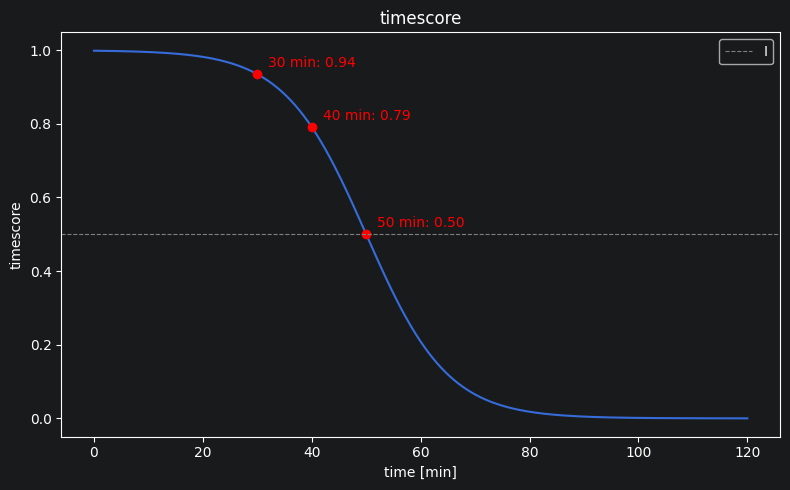

In [9]:
t = np.linspace(0, 120, 300)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(t, cook_timescore(t))
ax.plot(50, cook_timescore(50), "ro")
ax.annotate(f"{50} min: {cook_timescore(50):.2f}", (50, cook_timescore(50)), xytext=(8, 5), textcoords="offset points", color="red")
ax.plot(40, cook_timescore(40), "ro")
ax.annotate(f"{40} min: {cook_timescore(40):.2f}", (40, cook_timescore(40)), xytext=(8, 5), textcoords="offset points", color="red")
ax.plot(30, cook_timescore(30), "ro")
ax.annotate(f"{30} min: {cook_timescore(30):.2f}", (30, cook_timescore(30)), xytext=(8, 5), textcoords="offset points", color="red")
ax.axhline(0.5, color="gray", lw=0.8, ls="--",label="I")
ax.set(title="timescore", xlabel="time [min]", ylabel="timescore")
ax.legend()
plt.tight_layout()
plt.show()

 People tend have **flat**  numbers so some stepping points are makred

In [11]:
def taste_part(taste):
    return (np.asarray(taste) / 10) ** 1.5

def effort_part(taste, effort):
    cost = (np.asarray(effort) - 1) / 4
    return 1 - 0.5 * (np.asarray(taste) / 10) * cost

def reward(time, taste, effort):
    return 10 * cook_timescore(time) * taste_part(taste) * effort_part(taste, effort)

def reward_from_ratings(cook_minutes, prep_minutes, taste_ratings, effort_ratings):
    return reward(cook_minutes + prep_minutes, np.mean(taste_ratings), np.mean(effort_ratings))

**Taste** and **Effort** are balanced
As Effort Counts How much you need to clean how much attention you need to spend peraring amunt etc. (Personal Feeling)

– low taste is punished hard

$$
\text{taste\_part} = \left(\frac{taste}{10}\right)^{1.5} \qquad \text{cost} = \frac{effort }{10}
$$
**Effort** Goes from 0 no effort to 10 plenty of effort.
Taste is weighted independly but the effort rating should only be considered for tasty recipes bc non tasty have already
a shitty score.
$$
 \qquad \text{effort\_part} = 1 - 0.5 \cdot \frac{taste}{10} \cdot \text{cost}
$$
**Result**

$$
\text{reward} = 10 \cdot \text{timescore} \cdot \text{taste\_part} \cdot \text{effort\_part} \in [0, 10]
$$

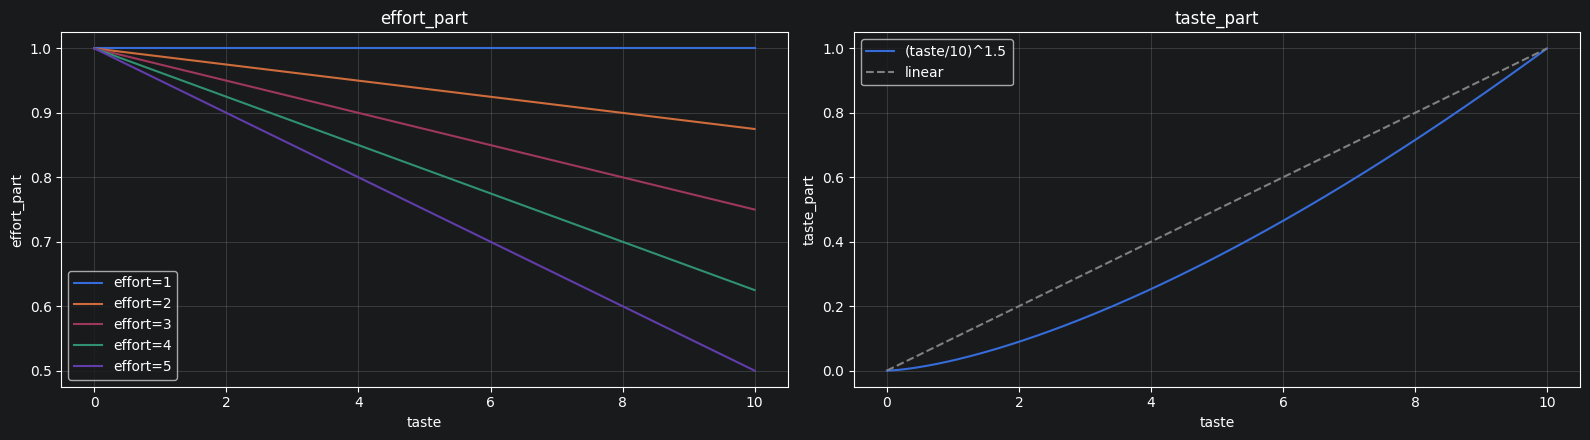

In [12]:
t = np.linspace(0, 120, 300)
ta = np.linspace(0, 10, 200)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

ax = axes[1]
ax.plot(ta, taste_part(ta), label="(taste/10)^1.5")
ax.plot(ta, ta / 10, ls="--", color="gray", label="linear")
ax.set(title="taste_part", xlabel="taste", ylabel="taste_part")
ax.legend()

ax = axes[0]
for e in [1, 2, 3, 4, 5]:
    ax.plot(ta, effort_part(ta, e), label=f"effort={e}")
ax.set(title="effort_part", xlabel="taste", ylabel="effort_part")
ax.legend()

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

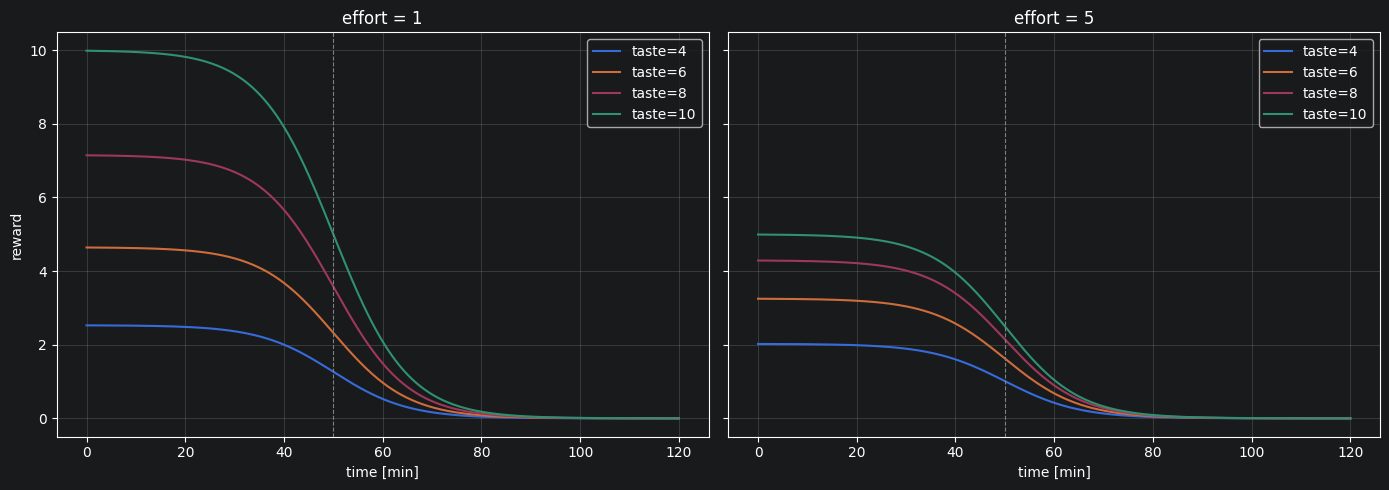

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, e in zip(axes, [1, 5]):
    for tv in [4, 6, 8, 10]:
        ax.plot(t, reward(t, tv, e), label=f"taste={tv}")
    ax.axvline(50, color="gray", lw=0.8, ls="--")
    ax.set(title=f"effort = {e}", xlabel="time [min]")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("reward")
plt.tight_layout()
plt.show()




The same-day filter (`cook_minutes` or `prep_minutes` > 60 → remove) is a hard filter, see II.4.

Idea:
- effort is a **penalty** (multiplied), not added.
- bad taste can't be saved by low effort.
- effort effect grows with taste: max. penalty = 50 % · taste / 10.

**Edge cases**

| Case | Handling |
|---|---|
| never cooked (no ratings) | `taste = 8`, `effort = 3`, `time = 45 min` |
| missing times | treat as 45 min |
| total time > 60 min (each part < 60) | passes the filter, but timescore makes the reward small |

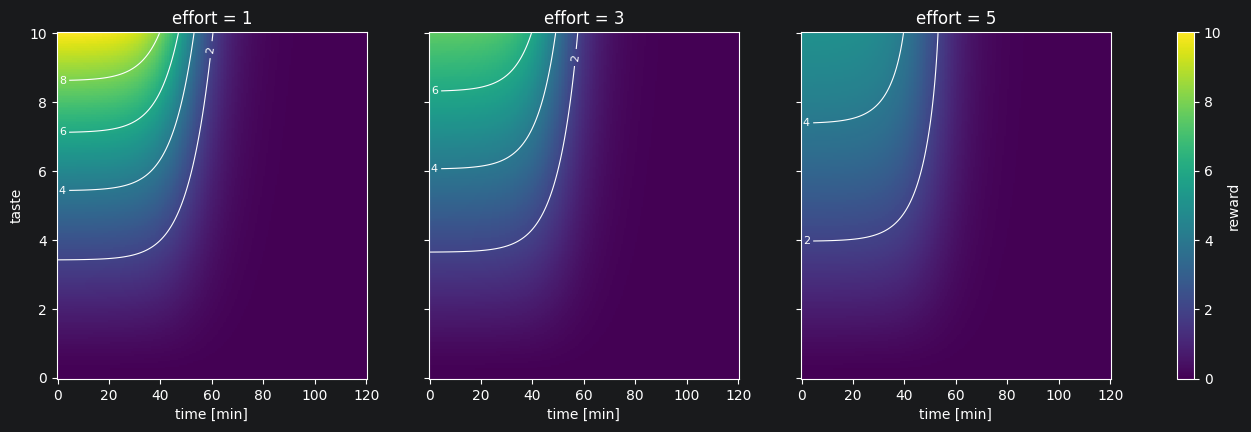

In [5]:
T, TA = np.meshgrid(np.linspace(0, 120, 200), np.linspace(0, 10, 200))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, e in zip(axes, [1, 3, 5]):
    Z = reward(T, TA, e)
    m = ax.pcolormesh(T, TA, Z, shading="auto", cmap="viridis", vmin=0, vmax=10)
    cs = ax.contour(T, TA, Z, levels=[2, 4, 6, 8], colors="white", linewidths=0.8)
    ax.clabel(cs, fontsize=8)
    ax.set(title=f"effort = {e}", xlabel="time [min]")
axes[0].set_ylabel("taste")
fig.colorbar(m, ax=axes, label="reward")
plt.show()

## Sanity Checks

Expected behavior. 🟠 = not tested yet; "old" = value from the old test script, re-check here.

| Situation | Expected | Status |
|---|---|---|
| quick & tasty & low effort | reward ≈ 10 | 🟠 old: 9.82 (20 min, taste 10, effort 1) |
| taste 0 | reward 0 | 🟠 |
| 50 min, otherwise perfect | reward halved | 🟠 |
| bad taste + low effort vs. great taste + high effort | great taste wins | 🟠 old: 0.88 < 4.91 |
| higher taste ⇒ higher reward | monotonically increasing | 🟠 |
| more effort ⇒ lower reward | monotonically decreasing | 🟠 |
| effort effect bad vs. tasty dish | smaller for bad dish | 🟠 old: −10 % vs. −50 % |